# Défi du Taux de Conversion - Data Science Weekly
## Prédiction des conversions d'abonnements à une newsletter

**Contexte :** www.datascienceweekly.org est une newsletter rédigée par des data scientists indépendants.  
L'objectif est de prédire si un visiteur va s'abonner à la newsletter, à partir de quelques variables comportementales.

---
## Plan du notebook
- **Partie 1** : Analyse exploratoire des données (EDA) et prétraitements - Modèle de base
- **Partie 2** : Amélioration du score F1 - Exploration de modèles avancés
- **Partie 3** : Prédictions sur les données de test et export
- **Partie 4** : Analyse des paramètres du meilleur modèle et recommandations

In [1]:
# ============================================================
# IMPORTS ET CONFIGURATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    f1_score, precision_score, recall_score, 
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight


from xgboost import XGBClassifier

---
## Partie 1 - Analyse exploratoire et modèle de base
### 1.1 Chargement des données

In [2]:
# ============================================================
# CHARGEMENT DES DONNÉES
# Les fichiers CSV sont placés dans le sous-dossier data/
# ============================================================
file_train_path = 'data/conversion_data_train.csv'
# Chargement du jeu d'entraînement (données étiquetées avec la colonne 'converted')
df_train = pd.read_csv(file_train_path)

print(f'Entraînement : {df_train.shape[0]:,} lignes x {df_train.shape[1]} colonnes')

print("\n=== Aperçu du jeu d'entraînement ===")
df_train.head(10)


Entraînement : 284,580 lignes x 6 colonnes

=== Aperçu du jeu d'entraînement ===


,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0
5,US,29,0,Seo,7,0
6,US,30,1,Direct,4,0
7,UK,38,1,Ads,2,0
8,UK,26,1,Seo,4,0
9,UK,31,0,Seo,5,0


### 1.2 Description des variables

| Variable | Type | Description |
|---|---|---|
| `country` | Catégorielle | Pays d'origine du visiteur (China, Germany, UK, US) |
| `age` | Numérique | Âge du visiteur |
| `new_user` | Binaire | 1 = nouvel utilisateur, 0 = utilisateur existant |
| `source` | Catégorielle | Source du trafic (Ads, Seo, Direct) |
| `total_pages_visited` | Numérique | Nombre de pages visitées lors de la session |
| `converted` | **Cible** (0/1) | 1 = abonné à la newsletter, 0 = non abonné |

In [3]:
# ============================================================
# INFORMATIONS GÉNÉRALES ET TYPES DE DONNÉES
# ============================================================

print('=== Types des colonnes ===')
print(df_train.dtypes)

print('\n=== Valeurs manquantes par colonne ===')
missing = df_train.isnull().sum()
display(missing)
print(f'\nAucune valeur manquante? --> {missing.sum() == 0}')

print('\n=== Statistiques descriptives (variables numériques) ===')
display(df_train.describe().round(2))

=== Types des colonnes ===
country                object
age                     int64
new_user                int64
source                 object
total_pages_visited     int64
converted               int64
dtype: object

=== Valeurs manquantes par colonne ===


country                0
age                    0
new_user               0
source                 0
total_pages_visited    0
converted              0
dtype: int64


Aucune valeur manquante? --> True

=== Statistiques descriptives (variables numériques) ===


,age,new_user,total_pages_visited,converted
count,284580.00,284580.00,284580.00,284580.00
mean,30.56,0.69,4.87,0.03
std,8.27,0.46,3.34,0.18
min,17.00,0.00,1.00,0.00
25%,24.00,0.00,2.00,0.00
50%,30.00,1.00,4.00,0.00
75%,36.00,1.00,7.00,0.00
max,123.00,1.00,29.00,1.00


In [4]:
print("Catégories de la colonne source:")
display(df_train["source"].value_counts())

print("Catégories de la colonne country:")
display(df_train["country"].value_counts())

print("Pourcentages des labels 0/1 de la target converted:")
display(df_train.groupby("converted")["converted"].count() * 100 / len(df_train))

Catégories de la colonne source:


source
Seo       139477
Ads        80027
Direct     65076
Name: count, dtype: int64

Catégories de la colonne country:


country
US         160124
China       69122
UK          43641
Germany     11693
Name: count, dtype: int64

Pourcentages des labels 0/1 de la target converted:


converted
0    96.774194
1     3.225806
Name: converted, dtype: float64

Le jeu de données est complet, sans aucune valeur manquante. Les variables "country" et "source" sont catégorielles (avec peu de labels) et vont être encodées. La variable"âge" présente un maximum à 123 ans, ce qui est manifestement aberrant et devra être traité. Le taux de souscription moyen est de 3,2%, ce qui confirme un fort déséquilibre des classes de la target "converted".

In [5]:
# ============================================================
# DÉTECTION DES VALEURS ABERRANTES
# ============================================================
# Suppression des lignes avec un âge manifestement aberrant (> 100 ans)
print(f"Nombe de valeurs aberrantes dans la colonne age: {len(df_train[df_train['age'] > 100])}")
df_train = df_train[df_train['age'] <= 100]
print(f'\nNombre de lignes après nettoyage : {df_train.shape[0]:,}')

Nombe de valeurs aberrantes dans la colonne age: 2

Nombre de lignes après nettoyage : 284,578


### 1.3 Analyse exploratoire des données (EDA)

Nombre total de visiteurs  : 284578
Nombre de conversions      : 9,178
Taux de conversion global  : 3.23%


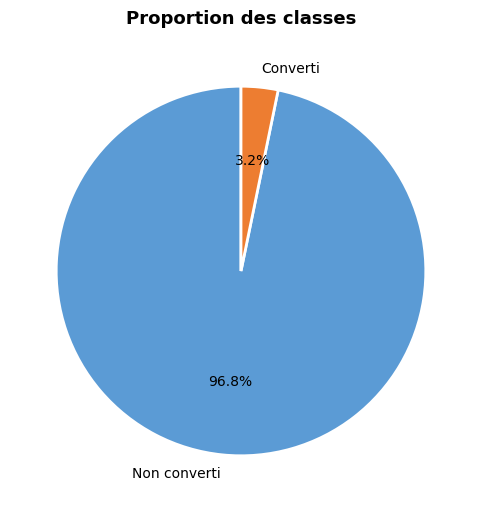

In [6]:
# ============================================================
# ANALYSE DE LA VARIABLE CIBLE
# ============================================================
taux_conversion = df_train['converted'].mean()
n_converted     = df_train['converted'].sum()

print(f'Nombre total de visiteurs  : {len(df_train)}')
print(f'Nombre de conversions      : {n_converted:,}')
print(f'Taux de conversion global  : {taux_conversion:.2%}')

fig, axe = plt.subplots(figsize=(9,6))
counts = df_train['converted'].value_counts().sort_index()

# Diagramme camembert
axe.pie(
    counts.values,
    labels=['Non converti', 'Converti'],
    autopct='%1.1f%%',
    colors=['#5B9BD5', '#ED7D31'],
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axe.set_title('Proportion des classes', fontsize=13, fontweight='bold', pad=12)
plt.show()


Le jeu de données est très déséquilibré. Seulement 3,2% des visiteurs s'abonnent à la newsletter. Ce déséquilibre doit être pris en compte lors de l'apprentissage.

--- age ---
              count   mean   std   min   25%   50%   75%   max
converted                                                     
0          275400.0  30.70  8.27  17.0  24.0  30.0  36.0  79.0
1            9178.0  26.55  6.96  17.0  21.0  25.0  31.0  61.0

--- total_pages_visited ---
              count   mean   std  min   25%   50%   75%   max
converted                                                    
0          275400.0   4.55  2.79  1.0   2.0   4.0   6.0  20.0
1            9178.0  14.56  3.96  2.0  12.0  14.0  17.0  29.0



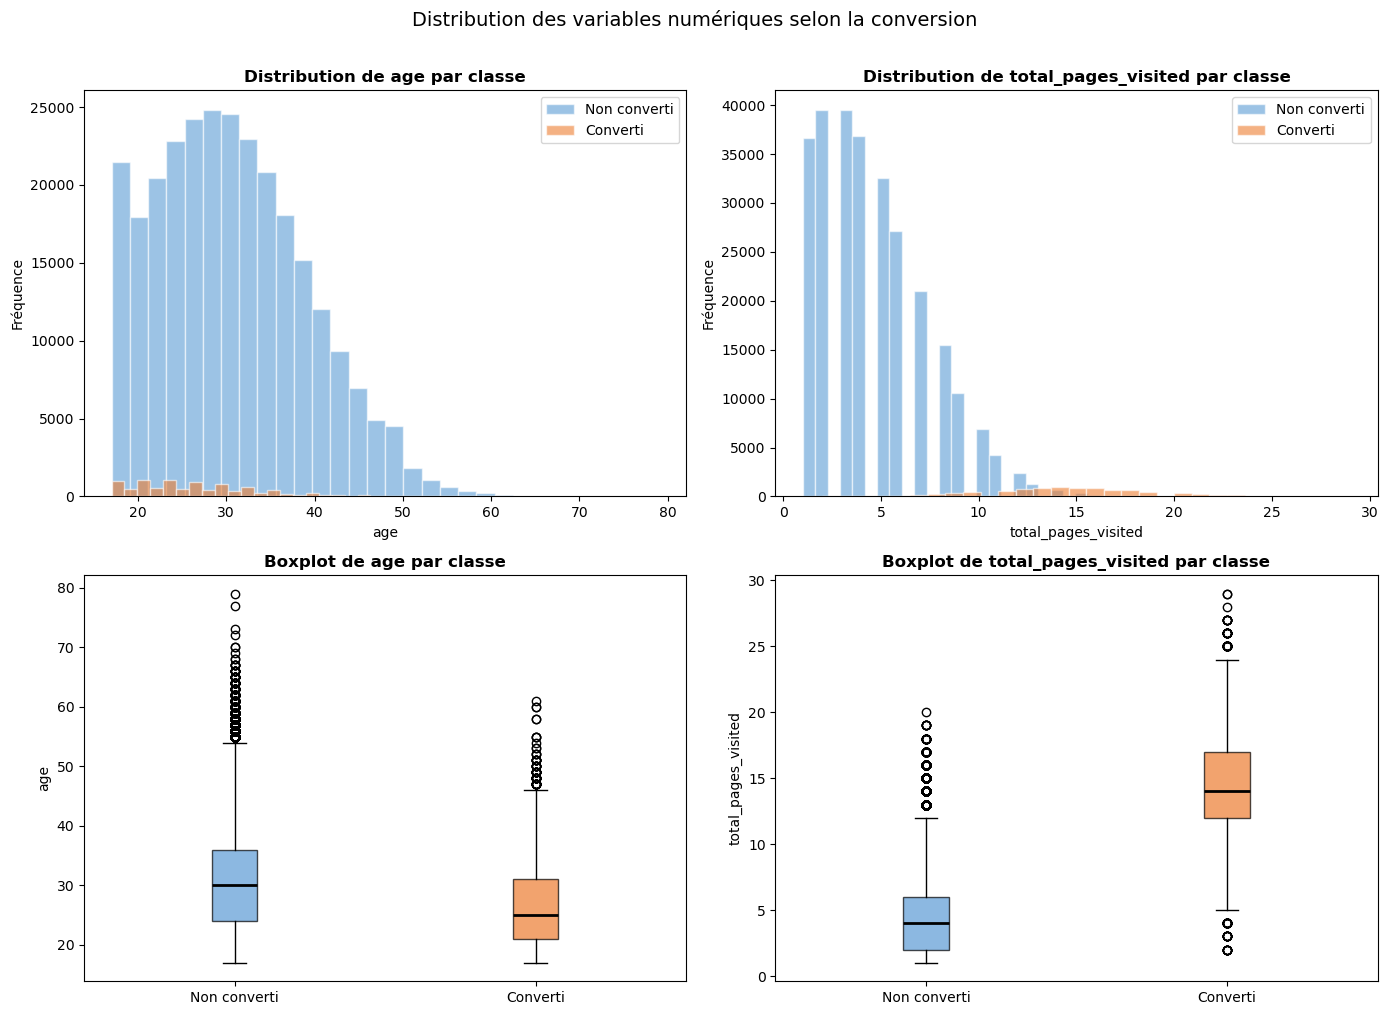

In [7]:
# ============================================================
# EDA - DISTRIBUTION DES VARIABLES NUMÉRIQUES PAR CLASSE
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

vars_num   = ['age', 'total_pages_visited']
couleur_0  = '#5B9BD5'
couleur_1  = '#ED7D31'

for i, var in enumerate(vars_num):
    # Histogramme superposé par classe
    for val, label, couleur in [(0, 'Non converti', couleur_0), (1, 'Converti', couleur_1)]:
        data = df_train[df_train['converted'] == val][var]
        axes[i].hist(data, bins=30, alpha=0.6, label=label, color=couleur, edgecolor='white')
    axes[i].set_title(f'Distribution de {var} par classe', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Fréquence')
    axes[i].legend()

    # Boxplot par classe
    ax_box = axes[i + 2]
    data_0 = df_train[df_train['converted'] == 0][var]
    data_1 = df_train[df_train['converted'] == 1][var]
    bp = ax_box.boxplot(
        [data_0, data_1],
        tick_labels=['Non converti', 'Converti'],
        patch_artist=True,
        medianprops={'color': 'black', 'linewidth': 2}
    )
    for patch, couleur in zip(bp['boxes'], [couleur_0, couleur_1]):
        patch.set_facecolor(couleur)
        patch.set_alpha(0.7)
    ax_box.set_title(f'Boxplot de {var} par classe', fontsize=12, fontweight='bold')
    ax_box.set_ylabel(var)

    # Statistiques comparatives
    print(f'--- {var} ---')
    print(df_train.groupby('converted')[var].describe().round(2))
    print()

plt.suptitle('Distribution des variables numériques selon la conversion', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

La variable total_pages_visited est très discriminante : les visiteurs convertis visitent en moyenne beaucoup plus de pages (médiane ~14) que les non convertis (médiane ~4). La variable âge montre une légère différence entre les deux classes : les visiteurs convertis sont légèrement plus jeunes.

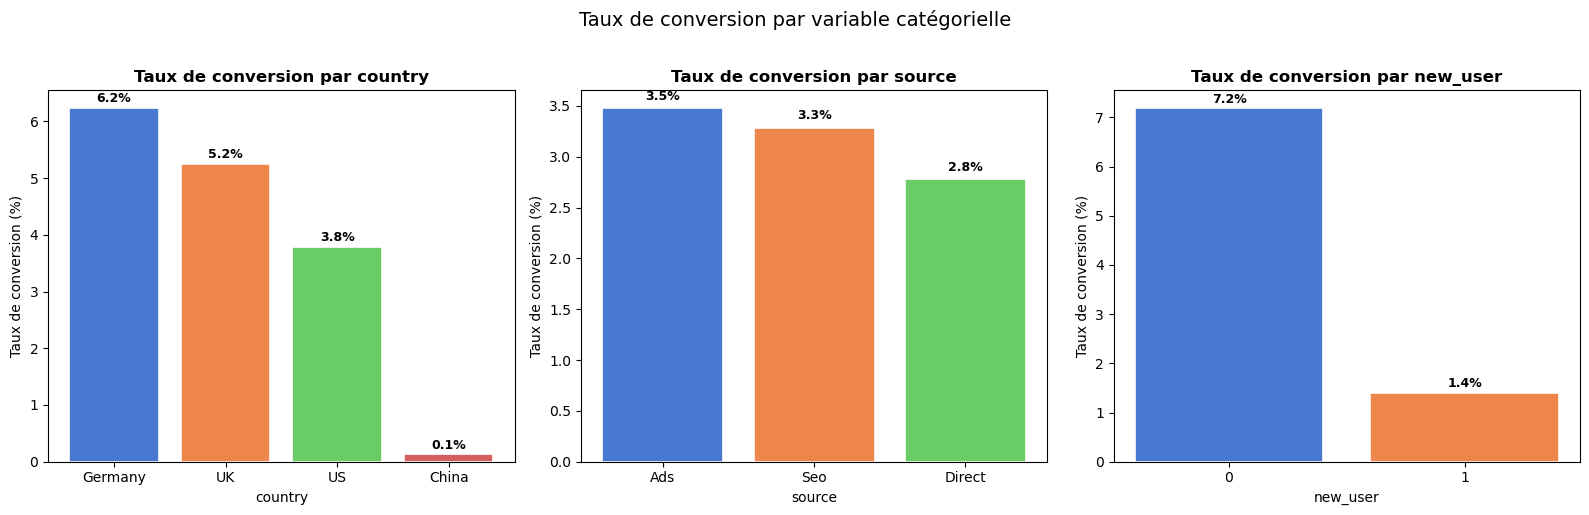

Statistiques détaillées :

--- country ---
        Taux de conversion  Nb visiteurs  Nb convertis
country                                               
China                0.13%         69122            89
Germany              6.24%         11692           729
UK                   5.25%         43640          2290
US                   3.79%        160124          6070

--- source ---
       Taux de conversion  Nb visiteurs  Nb convertis
source                                               
Ads                 3.48%         80026          2784
Direct              2.78%         65076          1810
Seo                 3.29%        139476          4584

--- new_user ---
         Taux de conversion  Nb visiteurs  Nb convertis
new_user                                               
0                     7.19%         89512          6437
1                     1.41%        195066          2741


In [8]:
# ============================================================
# EDA - TAUX DE CONVERSION PAR VARIABLE CATÉGORIELLE
# ============================================================
vars_cat = ['country', 'source', 'new_user']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, var in enumerate(vars_cat):
    taux = df_train.groupby(var)['converted'].mean().sort_values(ascending=False)
    barres = axes[i].bar(
        taux.index.astype(str),
        taux.values * 100,
        color=sns.color_palette('muted', len(taux)),
        edgecolor='white', linewidth=1.2
    )
    axes[i].set_title(f'Taux de conversion par {var}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Taux de conversion (%)')
    axes[i].set_xlabel(var)
    axes[i].tick_params(axis='x')
    for barre in barres:
        h = barre.get_height()
        axes[i].text(
            barre.get_x() + barre.get_width() / 2, h + 0.05,
            f'{h:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold'
        )

plt.suptitle('Taux de conversion par variable catégorielle', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print('Statistiques détaillées :')
for var in vars_cat:
    print(f'\n--- {var} ---')
    stats = df_train.groupby(var)['converted'].agg(['mean', 'count', 'sum'])
    stats.columns = ['Taux de conversion', 'Nb visiteurs', 'Nb convertis']
    stats['Taux de conversion'] = stats['Taux de conversion'].map('{:.2%}'.format)
    print(stats)


La Chine affiche un taux de conversion de seulement 0,1%, très éloigné des autres pays (Allemagne : 6,2%, UK : 5,2%). Les utilisateurs existants (new_user=0) convertissent à 7,2%, soit 5 fois plus que les nouveaux utilisateurs (1,4%). C'est logique : ils connaissent déjà le site et sont plus enclins à s'abonner.

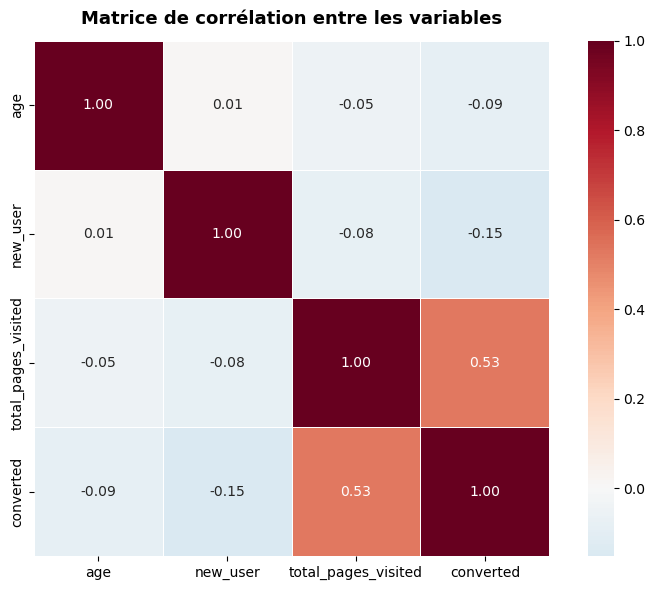

Corrélations avec la variable cible (converted) :
total_pages_visited    0.529
age                   -0.089
new_user              -0.152
Name: converted, dtype: float64


In [9]:
# ============================================================
# EDA - MATRICE DE CORRÉLATION
# ============================================================
df_corr = df_train.copy()

cols_corr    = ['age', 'new_user', 'total_pages_visited', 'converted']
corr_matrix  = df_corr[cols_corr].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0,
    linewidths=0.5,
    square=True,
    ax=ax
)
ax.set_title('Matrice de corrélation entre les variables', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print('Corrélations avec la variable cible (converted) :')
corr_cible = corr_matrix['converted'].drop('converted').sort_values(ascending=False)
print(corr_cible.round(3))


total_pages_visited est de loin la variable la plus corrélée avec la conversion (r = 0,53). Les autres paramètres ne sont pas corrélés à la conversion.

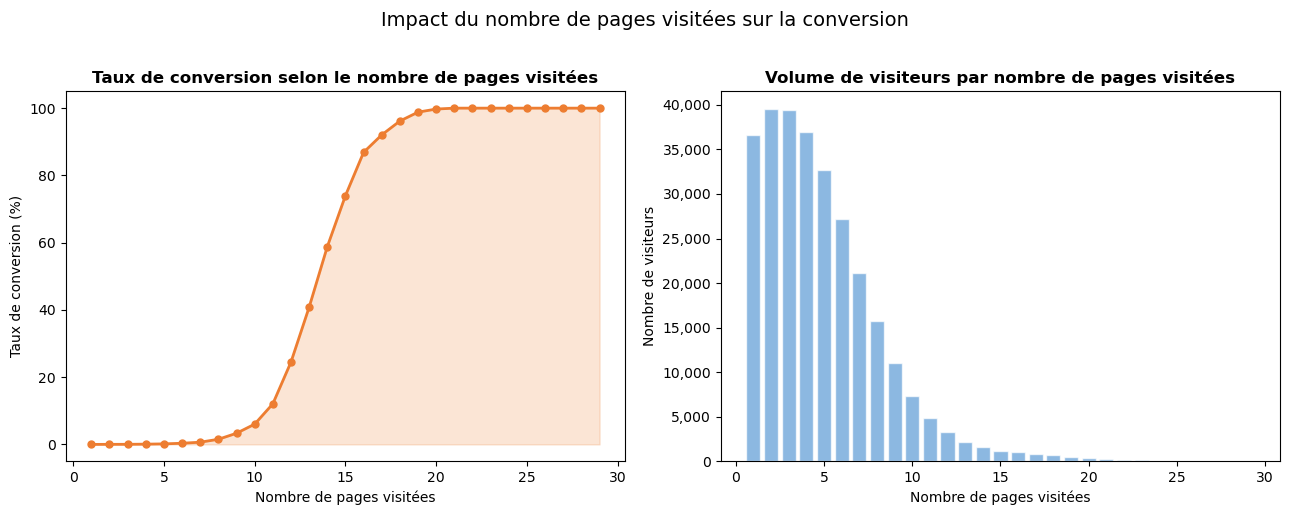

In [10]:
# ============================================================
# EDA - TAUX DE CONVERSION SELON LE NOMBRE DE PAGES VISITÉES
# ============================================================
conv_pages = df_train.groupby('total_pages_visited')['converted'].agg(
    taux_conversion='mean',
    nb_visiteurs='count'
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13,5))

# Courbe du taux de conversion par nombre de pages
axes[0].plot(
    conv_pages['total_pages_visited'],
    conv_pages['taux_conversion'] * 100,
    marker='o', markersize=5, linewidth=2, color='#ED7D31'
)
axes[0].fill_between(
    conv_pages['total_pages_visited'],
    conv_pages['taux_conversion'] * 100,
    alpha=0.2, color='#ED7D31'
)
axes[0].set_title('Taux de conversion selon le nombre de pages visitées',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nombre de pages visitées')
axes[0].set_ylabel('Taux de conversion (%)')

# Volume de visiteurs par nombre de pages
axes[1].bar(
    conv_pages['total_pages_visited'],
    conv_pages['nb_visiteurs'],
    color='#5B9BD5', alpha=0.7, edgecolor='white'
)
axes[1].set_title('Volume de visiteurs par nombre de pages visitées',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nombre de pages visitées')
axes[1].set_ylabel('Nombre de visiteurs')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.suptitle('Impact du nombre de pages visitées sur la conversion', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

La relation entre pages visitées et conversion est très marquée. À partir de 10 pages visitées, le taux de conversion dépasse 40%. Au-delà de 15 pages, il est proche de 100%. Cela confirme que **total_pages_visited sera la variable explicative dominante**.

### 1.4 Prétraitement des données

In [11]:
# ===================================================================
# PRÉTRAITEMENT DES DONNÉES (Modèle Baseline: Régression logistique)
# ===================================================================
cat_features = ['country', 'source']
num_features = ['age', 'new_user', 'total_pages_visited']
target = 'converted'

# Séparation features (numériques + catégorielles) / cible
X = df_train[num_features + cat_features]
y = df_train[target]

# Division entraînement / test (80% / 20%)
# stratify=y garantit la même proportion de convertis dans les deux ensembles
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalisation obligatoire pour la régression logistique + encodage des catégories
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first', handle_unknown='ignore')
featureencoder = ColumnTransformer(transformers=[
    ('cat', categorical_transformer, cat_features), 
    ('num', numeric_transformer, num_features)])


X_train = featureencoder.fit_transform(X_train)
X_test = featureencoder.transform(X_test)

### 1.5 Modèle de base : Régression logistique

=== Régression logistique - class_weight="balanced" ===
----Train-----
Score F1  : 0.5118
ROC-AUC   : 0.9859

Rapport de classification :
              precision    recall  f1-score   support

Non converti       1.00      0.94      0.97    220320
    Converti       0.35      0.94      0.51      7342

    accuracy                           0.94    227662
   macro avg       0.67      0.94      0.74    227662
weighted avg       0.98      0.94      0.95    227662


----Test-----
Score F1  : 0.5115
ROC-AUC   : 0.9859

Rapport de classification :
              precision    recall  f1-score   support

Non converti       1.00      0.94      0.97     55080
    Converti       0.35      0.94      0.51      1836

    accuracy                           0.94     56916
   macro avg       0.67      0.94      0.74     56916
weighted avg       0.98      0.94      0.95     56916



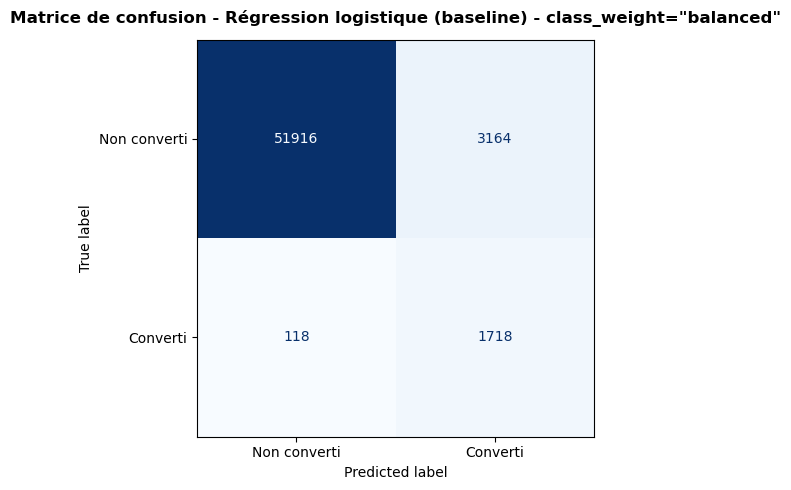

In [12]:
# ======================================================================
# MODÈLE DE BASE - RÉGRESSION LOGISTIQUE ave le paramètre class_weight
# ======================================================================
lr_baseline = LogisticRegression(class_weight='balanced')
lr_baseline.fit(X_train, y_train)

y_pred_train_lr = lr_baseline.predict(X_train)
y_pred_test_lr = lr_baseline.predict(X_test)

f1_train_lr  = f1_score(y_train, y_pred_train_lr)
auc_train_lr = roc_auc_score(y_train, lr_baseline.predict_proba(X_train)[:, 1])
f1_test_lr  = f1_score(y_test, y_pred_test_lr)
auc_test_lr = roc_auc_score(y_test, lr_baseline.predict_proba(X_test)[:, 1])

print('=== Régression logistique - class_weight="balanced" ===')
print("----Train-----")
print(f'Score F1  : {f1_train_lr:.4f}')
print(f'ROC-AUC   : {auc_train_lr:.4f}')
print('\nRapport de classification :')
print(classification_report(y_train, y_pred_train_lr, target_names=['Non converti', 'Converti']))
print()
print("----Test-----")
print(f'Score F1  : {f1_test_lr:.4f}')
print(f'ROC-AUC   : {auc_test_lr:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_test_lr, target_names=['Non converti', 'Converti']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_lr,
    display_labels=['Non converti', 'Converti'],
    colorbar=False, ax=ax, cmap='Blues'
)
ax.set_title('Matrice de confusion - Régression logistique (baseline) - class_weight="balanced"',
             fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


Même si les scores de l'accuracy(94%) et du ROC-AUC(98%) sont trés bons, `le F1-score de 0.51 est moyen: on a un deséquilibre entre la précion 35% très basse, et le recall 94% haut.`

**Ceci est dû au paramètre class_weight="balanced". Comme le modèle pendant l'apprentissage pénalise beaucoup les erreurs sur la classification de la classe 1 (converti), il va essayer de classer correctement la classe 1 au prix de beaucoup moins bien classer la classe 0 (non converti), dans le seul but de minimiser la cost function. Ainsi, on voit bien que les Faux Négatives sont peu nombreux, et les Faux positives sont nombreux.** 

=== Régression logistique - sans class_weight ===
----Train-----
Score F1  : 0.7644
ROC-AUC   : 0.9859

Rapport de classification :
              precision    recall  f1-score   support

Non converti       0.99      1.00      0.99    220320
    Converti       0.85      0.69      0.76      7342

    accuracy                           0.99    227662
   macro avg       0.92      0.84      0.88    227662
weighted avg       0.99      0.99      0.99    227662


----Test-----
Score F1  : 0.7604
ROC-AUC   : 0.9859

Rapport de classification :
              precision    recall  f1-score   support

Non converti       0.99      1.00      0.99     55080
    Converti       0.86      0.68      0.76      1836

    accuracy                           0.99     56916
   macro avg       0.93      0.84      0.88     56916
weighted avg       0.99      0.99      0.99     56916



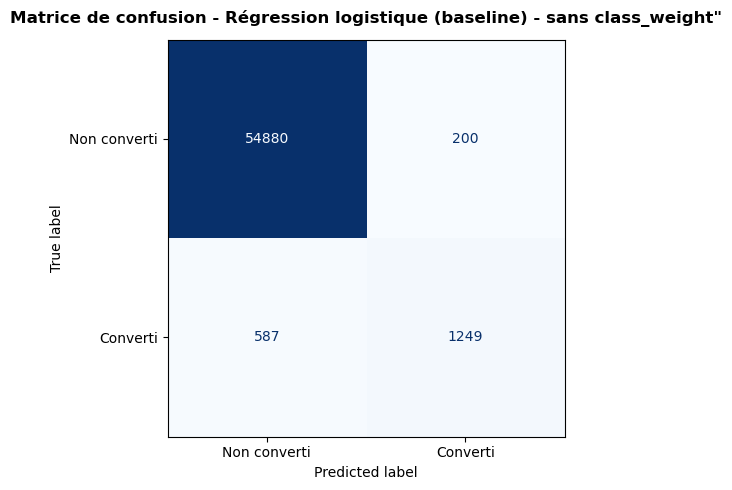

In [13]:
# ======================================================================
# MODÈLE DE BASE - RÉGRESSION LOGISTIQUE sans le paramètre class_weight
# ======================================================================
lr_baseline = LogisticRegression()
lr_baseline.fit(X_train, y_train)

y_pred_train_lr = lr_baseline.predict(X_train)
y_pred_test_lr = lr_baseline.predict(X_test)

f1_train_lr  = f1_score(y_train, y_pred_train_lr)
auc_train_lr = roc_auc_score(y_train, lr_baseline.predict_proba(X_train)[:, 1])
f1_test_lr  = f1_score(y_test, y_pred_test_lr)
prec_test_lr  = precision_score(y_test, y_pred_test_lr)
rec_test_lr  = recall_score(y_test, y_pred_test_lr)
auc_test_lr = roc_auc_score(y_test, lr_baseline.predict_proba(X_test)[:, 1])

print('=== Régression logistique - sans class_weight ===')
print("----Train-----")
print(f'Score F1  : {f1_train_lr:.4f}')
print(f'ROC-AUC   : {auc_train_lr:.4f}')
print('\nRapport de classification :')
print(classification_report(y_train, y_pred_train_lr, target_names=['Non converti', 'Converti']))
print()
print("----Test-----")
print(f'Score F1  : {f1_test_lr:.4f}')
print(f'ROC-AUC   : {auc_test_lr:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_test_lr, target_names=['Non converti', 'Converti']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_lr,
    display_labels=['Non converti', 'Converti'],
    colorbar=False, ax=ax, cmap='Blues'
)
ax.set_title('Matrice de confusion - Régression logistique (baseline) - sans class_weight"',
             fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

Sans l'utilisation du class_weight, `on obtient un F1 score de 76% assez correct, et équilibré: la précision 86% s'est améliorée, en perdant naturellement un peu sur le recall de 68%.` On notera aussi que les résultats sur le train et le test sont pareils --> **pas d'overfitting**.

Le score de l'accuracy dans ce projet, sur ce dateset, n'est pas représentatif à cause du grand deséquilibre entre les classes. Par conséquent, on s'intéressera qu'au score F1.

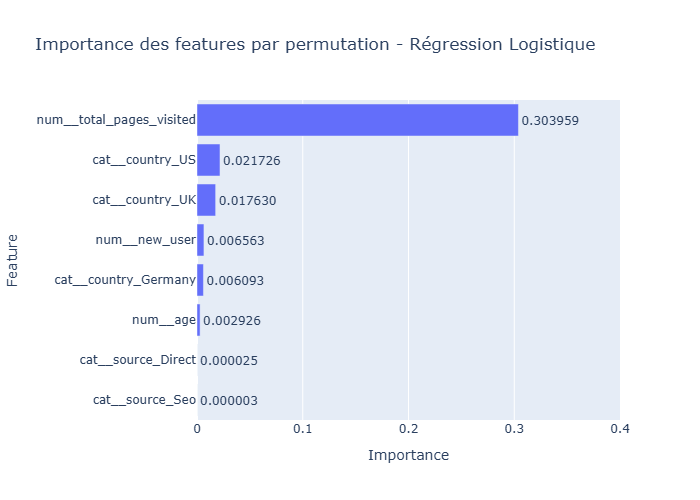

In [14]:
# Analyse de la Features Importance
# On utilise la méthode par permutation --> Mean Decrease Accuracy (MDA)
features = featureencoder.get_feature_names_out()
result = permutation_importance(lr_baseline, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42)
df_importances = pd.DataFrame({
    'Feature': features,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=True)

# Graphique barres horizontales
fig = px.bar(
    df_importances,
    x='Importance',
    y='Feature',
    orientation='h',
    title="Importance des features par permutation - Régression Logistique",
    text='Importance'
)
fig.update_traces(texttemplate='%{text:.6f}', textposition='outside')
fig.update_layout(showlegend=False, xaxis={'range': [0, 0.4]})
fig.show(renderer='png')

Comme remarqué pendant l'EDA, on voit bien que le modèle se base presque exclusivement sur la variable "total_pages_visited".

---
## Partie 2 - Amélioration du score F1
### 2.1 Random Forest

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Meilleurs paramètres : {'class_weight': {0: 1, 1: 2}, 'max_depth': 10, 'min_samples_leaf': 20, 'n_estimators': 100}
Meilleur F1 moyen en validation croisée : 0.7673945487591619
=== Random Forest ===
----Train-----
Score F1  : 0.7743
ROC-AUC   : 0.9879

Rapport de classification :
              precision    recall  f1-score   support

Non converti       0.99      0.99      0.99    220320
    Converti       0.79      0.76      0.77      7342

    accuracy                           0.99    227662
   macro avg       0.89      0.88      0.88    227662
weighted avg       0.99      0.99      0.99    227662


----Test-----
Score F1  : 0.7613
ROC-AUC   : 0.9839

Rapport de classification :
              precision    recall  f1-score   support

Non converti       0.99      0.99      0.99     55080
    Converti       0.78      0.74      0.76      1836

    accuracy                           0.99     56916
   macro avg       0.89      

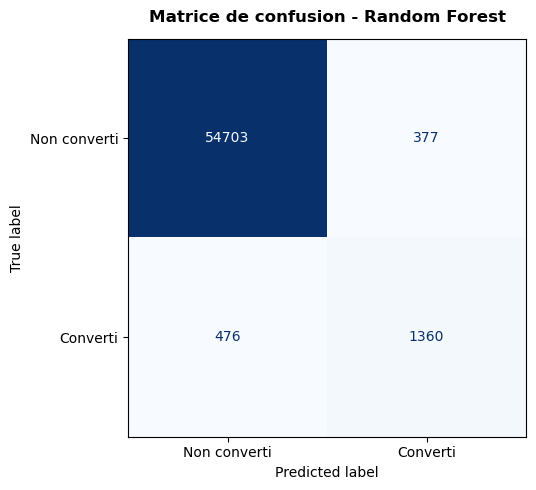

In [15]:
# ============================================================
# MODÈLE RANDOM FOREST + GridSearchCV
# ============================================================
# Random forest entraîne de nombreux arbres de décision
# indépendants et agrège leurs prédictions (vote majoritaire).
# Pas besoin de normaliser les données numériques.
# Besoin d'encoder les données catégorielles (one hot encoding sans retirer de catégotrie).
target = 'converted'
df_train_rf = df_train.copy()

# --- Séparation features (numériques + catégorielles) / cible ---
X = df_train_rf.drop(columns=target)
y = df_train_rf[target]

# --- Division train / test (80% / 20%) ---
# stratify=y garantit la même proportion de convertis dans les deux ensembles
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train = pd.get_dummies(X_train, columns=['country', 'source'])
X_test = pd.get_dummies(X_test, columns=['country', 'source'])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)
# Grille des hyperparamètres à tester
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 20, None],
    'min_samples_leaf': [5, 10, 20],
    'class_weight': [None, {0: 1, 1: 2}, {0: 1, 1: 3}]
}
# Grid Search avec validation croisée
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# Meilleur modèle
best_rf = grid_search.best_estimator_
print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur F1 moyen en validation croisée :", grid_search.best_score_)

y_pred_train_rf = best_rf.predict(X_train)
y_pred_test_rf = best_rf.predict(X_test)

f1_train_rf  = f1_score(y_train, y_pred_train_rf)
auc_train_rf = roc_auc_score(y_train, best_rf.predict_proba(X_train)[:, 1])
f1_test_rf  = f1_score(y_test, y_pred_test_rf)
prec_test_rf  = precision_score(y_test, y_pred_test_rf)
rec_test_rf  = recall_score(y_test, y_pred_test_rf)
auc_test_rf = roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1])

print('=== Random Forest ===')
print("----Train-----")
print(f'Score F1  : {f1_train_rf:.4f}')
print(f'ROC-AUC   : {auc_train_rf:.4f}')
print('\nRapport de classification :')
print(classification_report(y_train, y_pred_train_rf, target_names=['Non converti', 'Converti']))
print()
print("----Test-----")
print(f'Score F1  : {f1_test_rf:.4f}')
print(f'ROC-AUC   : {auc_test_rf:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_test_rf, target_names=['Non converti', 'Converti']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_rf,
    display_labels=['Non converti', 'Converti'],
    colorbar=False, ax=ax, cmap='Blues'
)
ax.set_title('Matrice de confusion - Random Forest',
             fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

Même s'il y a une très légère amélioration du score F1 (marginale), on note qu'il est mieux équilibré que dans le modèle baseline entre: une précision de 78% et un recall de 74%. Le modèle RF réduit aussi bien les FP que les FN.

Comme les scores entre train et test sont trés proches, il n'y a **pas d'overfitting**.

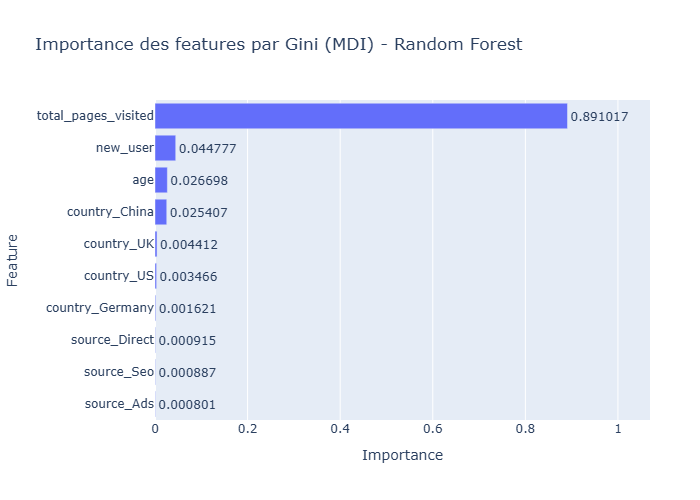

In [17]:
# Analyse de la Features Importance par Gini (MDI)
features = X_train.columns
importances = best_rf.feature_importances_

df_importances = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Graphique barres horizontales
fig = px.bar(
    df_importances,
    x='Importance',
    y='Feature',
    orientation='h',
    title="Importance des features par Gini (MDI) - Random Forest",
    text='Importance'
)
fig.update_traces(texttemplate='%{text:.6f}', textposition='outside')

max_val = df_importances['Importance'].max()
fig.update_layout(
    showlegend=False, 
    xaxis={'range': [0, max_val * 1.2]},
    margin=dict(r=50)
)

fig.show(renderer='png')

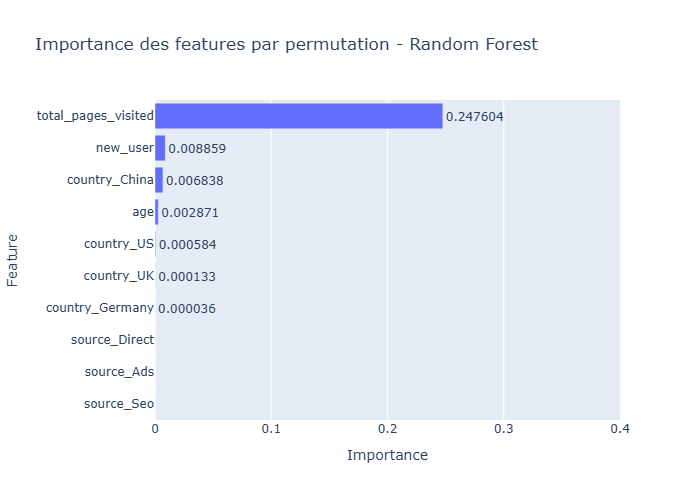

In [18]:
# Analyse de la Features Importancepar la méthode de permutation --> Mean Decrease Accuracy (MDA)
features = X_train.columns
result = permutation_importance(best_rf, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42)
df_importances = pd.DataFrame({
    'Feature': features,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=True)

# Graphique barres horizontales
fig = px.bar(
    df_importances,
    x='Importance',
    y='Feature',
    orientation='h',
    title="Importance des features par permutation - Random Forest",
    text='Importance'
)
fig.update_traces(texttemplate='%{text:.6f}', textposition='outside')
fig.update_layout(showlegend=False, xaxis={'range': [0, 0.4]})
fig.show(renderer='png')

La feature importance reste largement dominée par "total_pages_visited" vue qu'elle est fortement corrélée à la conversion.

### 2.2 Gradient Boosting (GXBoost)

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Meilleurs paramètres : {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 200, 'scale_pos_weight': 2, 'subsample': 0.8}
Meilleur score F1 moyen (CV) : 0.7704
=== Gradient Boosting ===
----Train-----
Score F1  : 0.7755
ROC-AUC   : 0.9867

Rapport de classification :
              precision    recall  f1-score   support

Non converti       0.99      0.99      0.99    220320
    Converti       0.81      0.74      0.78      7342

    accuracy                           0.99    227662
   macro avg       0.90      0.87      0.88    227662
weighted avg       0.99      0.99      0.99    227662


----Test-----
Score F1  : 0.7650
ROC-AUC   : 0.9851

Rapport de classification :
              precision    recall  f1-score   support

Non converti       0.99      0.99      0.99     55080
    Converti       0.81      0.73      0.76      1836

    accuracy                           0.99     56916
   macro avg       0.90      0.86      

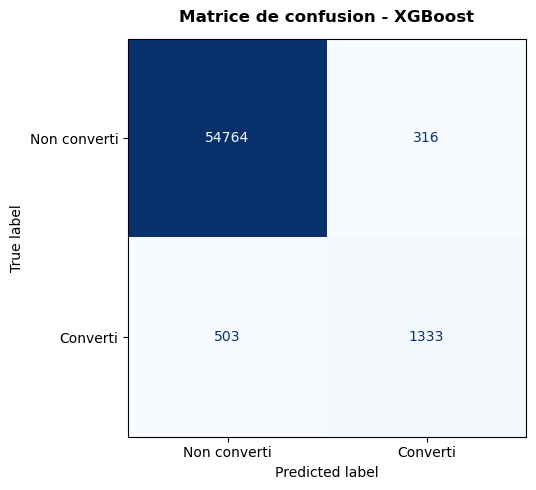

In [19]:
# ============================================================
# MODÈLE XGBoost + GridSearchCV
# ============================================================
# Le Gradient Boosting construit les arbres de façon séquentielle :
# chaque nouvel arbre corrige les erreurs du précédent.
# Chaque nouvel arbre est entraîné non pas sur les données brutes, 
# mais sur les résidus.

target = 'converted'
df_train_xgb = df_train.copy()
# --- Séparation features (numériques + catégorielles) / cible ---
X = df_train_xgb.drop(columns=target)
y = df_train_xgb[target]
# --- Division train / test (80% / 20%) ---
# stratify=y garantit la même proportion de convertis dans les deux ensembles
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Features engineering
# On divise l'âge par tranches
X_train['age_group'] = pd.cut(
    X_train['age'],
    bins=[0, 25, 35, 50, 100],
    labels=['young', 'adult', 'mature', 'senior']
).astype(str)
# Ratio pages visitées / âge 
X_train['pages_per_age'] = X_train['total_pages_visited'] / (X_train['age'] + 1)
X_train = pd.get_dummies(
    X_train,
    columns=['source', 'age_group', 'country']
)
X_train = X_train.drop(columns=['age'])
# On divise l'âge par tranches
X_test['age_group'] = pd.cut(
    X_test['age'],
    bins=[0, 25, 35, 50, 100],
    labels=['young', 'adult', 'mature', 'senior']
).astype(str)
# Ratio pages visitées / âge 
X_test['pages_per_age'] = X_test['total_pages_visited'] / (X_test['age'] + 1)
X_test = pd.get_dummies(
    X_test,
    columns=['source', 'age_group', 'country']
)
X_test = X_test.drop(columns=['age'])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

xgb_model = XGBClassifier(
    random_state=42,
    n_jobs=-1
)
# Grille des hyperparamètres
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 7, 10, None],
    'learning_rate': [0.01, 0.1, 0.5],
    'subsample': [0.8, 1.0],
    "scale_pos_weight": [2, None]
}
# Grid Search avec validation croisée (5 folds)
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# Meilleurs hyperparamètres
print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur score F1 moyen (CV) :", round(grid_search.best_score_, 4))
# Meilleur modèle
best_xgb_model = grid_search.best_estimator_

y_pred_train_xgb = best_xgb_model.predict(X_train)
y_pred_test_xgb = best_xgb_model.predict(X_test)

f1_train_xgb  = f1_score(y_train, y_pred_train_xgb)
auc_train_xgb = roc_auc_score(y_train, best_xgb_model.predict_proba(X_train)[:, 1])
f1_test_xgb  = f1_score(y_test, y_pred_test_xgb)
prec_test_xgb  = precision_score(y_test, y_pred_test_xgb)
rec_test_xgb  = recall_score(y_test, y_pred_test_xgb)
auc_test_xgb = roc_auc_score(y_test, best_xgb_model.predict_proba(X_test)[:, 1])

print('=== Gradient Boosting ===')
print("----Train-----")
print(f'Score F1  : {f1_train_xgb:.4f}')
print(f'ROC-AUC   : {auc_train_xgb:.4f}')
print('\nRapport de classification :')
print(classification_report(y_train, y_pred_train_xgb, target_names=['Non converti', 'Converti']))
print()
print("----Test-----")
print(f'Score F1  : {f1_test_xgb:.4f}')
print(f'ROC-AUC   : {auc_test_xgb:.4f}')
print('\nRapport de classification :')
print(classification_report(y_test, y_pred_test_xgb, target_names=['Non converti', 'Converti']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_xgb,
    display_labels=['Non converti', 'Converti'],
    colorbar=False, ax=ax, cmap='Blues'
)
ax.set_title('Matrice de confusion - XGBoost',
             fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


Le modèle XGBoost améliore légèrement le F1 score 76.5% par rapport au Rnadom Forest, en attribuant 81% à la précison et 73% au recall. 

Pareil que pour les précédents modèles, il n'y a **pas d'overfitting**.

### 2.3 Comparaison des modèles

=== Comparaison des modèles ===
               Modèle  Score F1  Precision  Recall
              XGBoost    0.7650     0.8084  0.7260
        Random Forest    0.7613     0.7830  0.7407
Régression logistique    0.7604     0.8620  0.6803



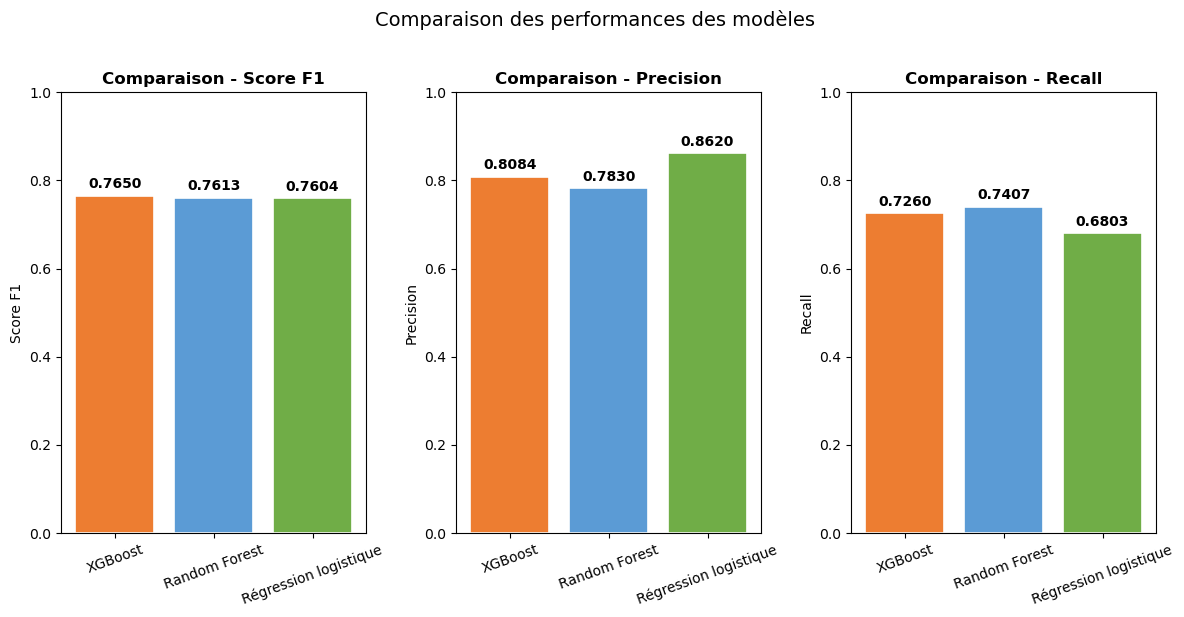

In [23]:
# ============================================================
# COMPARAISON DES MODÈLES - TABLEAU ET GRAPHIQUES
# ============================================================

resultats = pd.DataFrame({
    'Modèle'   : ['Régression logistique', 'Random Forest', 'XGBoost'],
    'Score F1'  : [f1_test_lr,  f1_test_rf,  f1_test_xgb],
    'Precision'   : [prec_test_lr, prec_test_rf, prec_test_xgb],
    'Recall'   : [rec_test_lr, rec_test_rf, rec_test_xgb]
})
resultats = resultats.sort_values('Score F1', ascending=False).reset_index(drop=True)

print('=== Comparaison des modèles ===')
print(resultats.to_string(index=False, float_format='{:.4f}'.format))
print()

# Graphique comparatif
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
couleurs = ['#ED7D31', '#5B9BD5', '#70AD47']

for ax, metrique in zip(axes, ['Score F1', 'Precision', 'Recall']):
    barres = ax.bar(
        resultats['Modèle'], resultats[metrique],
        color=couleurs[:len(resultats)],
        edgecolor='white', linewidth=1.2
    )
    ax.set_title(f'Comparaison - {metrique}', fontsize=12, fontweight='bold')
    ax.set_ylabel(metrique)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=20)
    for barre in barres:
        h = barre.get_height()
        ax.text(
            barre.get_x() + barre.get_width() / 2, h + 0.01,
            f'{h:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold'
        )

plt.suptitle('Comparaison des performances des modèles', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


Les trois modèles sont très proches en terme de F1 score. Une légère amélioration dans le XGBoost. 

RF et XGBoost ont un F1 score mieux équilibré (entre précision et recall) que la régression logistique.

`Pour ce challenge, le choix se dirige vers le XGBoost qui semble donner le meilleur compromis entre socre F1 et équilibre précision/recall.`

---
## Partie 3 - Prédictions sur les données de test
### 3.1 Génération et export des prédictions

In [24]:
# ============================================================
# Réentrainement du meilleur modèle sur tout le dataset train
# ============================================================
# On ré-entraîne le meilleur modèle sur la TOTALITÉ des données
# d'entraînement avant de prédire sur le test.

# --- Séparation features (numériques + catégorielles) / cible ---
X_train = df_train.drop(columns='converted')
y_train = df_train['converted']

# Features engineering
# On divise l'âge par tranches
X_train['age_group'] = pd.cut(
    X_train['age'],
    bins=[0, 25, 35, 50, 100],
    labels=['young', 'adult', 'mature', 'senior']
).astype(str)
# Ratio pages visitées / âge 
X_train['pages_per_age'] = X_train['total_pages_visited'] / (X_train['age'] + 1)
X_train = pd.get_dummies(
    X_train,
    columns=['source', 'age_group', 'country']
)
X_train = X_train.drop(columns=['age'])

# Chosen model (XGBoost)
best_model = XGBClassifier(
    n_estimators=200,
    max_depth=7,
    learning_rate=0.01,
    subsample=0.8,
    scale_pos_weight=2,
    random_state=42,
    n_jobs=-1
)

# Entrainement sur tout les data train
best_model.fit(X_train, y_train)

# ============================================================
# Inférence avec le  meilleur modèle sur le dataset test
# ============================================================
# Chargement des données test
file_test_path = 'data/conversion_data_test.csv'
X_test = pd.read_csv(file_test_path)
# Features engineering
# On divise l'âge par tranches
X_test['age_group'] = pd.cut(
    X_test['age'],
    bins=[0, 25, 35, 50, 100],
    labels=['young', 'adult', 'mature', 'senior']
).astype(str)
# Ratio pages visitées / âge 
X_test['pages_per_age'] = X_test['total_pages_visited'] / (X_test['age'] + 1)
X_test = pd.get_dummies(
    X_test,
    columns=['source', 'age_group', 'country']
)
X_test = X_test.drop(columns=['age'])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

#Inférence
y_pred_test  = best_model.predict(X_test)

# Soumettre les résultats
df_predictions = pd.DataFrame({'converted': y_pred_test})
df_predictions.to_csv('predictions_soumission.csv', index=False)
print('\nFichier exporté : predictions_soumission.csv')


Fichier exporté : predictions_soumission.csv


---
## Partie 4 - Analyse du meilleur modèle et recommandations
### 4.1 Importance des variables

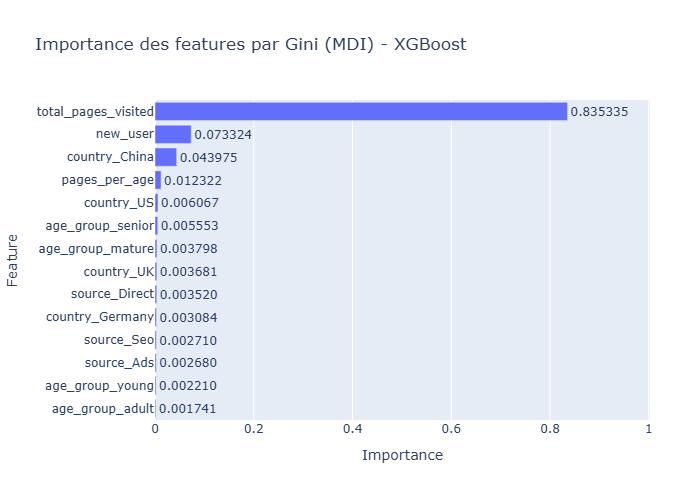

In [25]:
# Analyse de la Features Importance par Gini (MDI)
features = X_train.columns
importances = best_model.feature_importances_

df_importances = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Graphique barres horizontales
fig = px.bar(
    df_importances,
    x='Importance',
    y='Feature',
    orientation='h',
    title="Importance des features par Gini (MDI) - XGBoost",
    text='Importance'
)
fig.update_traces(texttemplate='%{text:.6f}', textposition='outside')

max_val = df_importances['Importance'].max()
fig.update_layout(
    showlegend=False, 
    xaxis={'range': [0, max_val * 1.2]},
    margin=dict(r=50)
)

fig.show(renderer='png')

total_pages_visited reste de très loin le prédicteur dominant (83.5 % de l'importance). La variable new_user pèse à 7.4 %. Avec l'encodage one-hot, l'effet du pays se concentre sur la colonne country_China (4.4%) : c'est bien la Chine, avec son taux de conversion anormal de 0,1 %, qui porte l'essentiel du signal lié au pays.

### 4.2 Leviers d'action

=== Taux de conversion par segment de pages visitées ===
              Taux de conversion  Nb visiteurs  Nb convertis
segment_pages                                               
1-3 pages                   0.0%        115648            20
4-7 pages                   0.3%        117882           313
8-15 pages                 10.9%         47127          5148
16+ pages                  94.3%          3921          3697



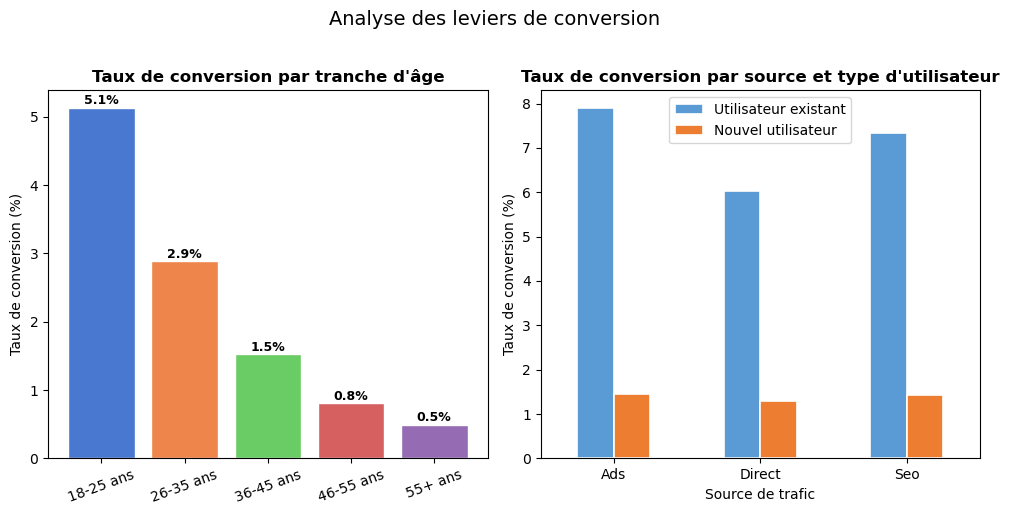

In [26]:
# ============================================================
# ANALYSE DES LEVIERS D'ACTION
# ============================================================
# On cherche à identifier des actions concrètes que l'équipe
# du site pourrait mettre en place pour améliorer le taux de conversion.

# Segmentation par nombre de pages visitées
df_train['segment_pages'] = pd.cut(
    df_train['total_pages_visited'],
    bins=[0, 3, 7, 15, 30],
    labels=['1-3 pages', '4-7 pages', '8-15 pages', '16+ pages']
)
conv_segment = df_train.groupby('segment_pages', observed=True)['converted'].agg(
    ['mean', 'count', 'sum']
).rename(columns={'mean': 'Taux de conversion', 'count': 'Nb visiteurs', 'sum': 'Nb convertis'})
conv_segment['Taux de conversion'] = conv_segment['Taux de conversion'].map('{:.1%}'.format)
print('=== Taux de conversion par segment de pages visitées ===')
print(conv_segment.to_string())
print()

# Graphiques des leviers
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Taux de conversion par tranche d'âge
df_train['tranche_age'] = pd.cut(
    df_train['age'],
    bins=[17, 25, 35, 45, 55, 100],
    labels=['18-25 ans', '26-35 ans', '36-45 ans', '46-55 ans', '55+ ans']
)
conv_age    = df_train.groupby('tranche_age', observed=True)['converted'].mean() * 100
barres_age  = axes[0].bar(
    conv_age.index, conv_age.values,
    color=sns.color_palette('muted', len(conv_age)),
    edgecolor='white'
)
axes[0].set_title('Taux de conversion par tranche d\'âge', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Taux de conversion (%)')
axes[0].tick_params(axis='x', rotation=20)
for barre in barres_age:
    h = barre.get_height()
    axes[0].text(
        barre.get_x() + barre.get_width() / 2, h + 0.05,
        f'{h:.1f}%', ha='center', fontsize=9, fontweight='bold'
    )

# Taux de conversion par source et type d'utilisateur
conv_source_user = (
    df_train.groupby(['source', 'new_user'])['converted']
    .mean()
    .unstack() * 100
)
conv_source_user.columns = ['Utilisateur existant', 'Nouvel utilisateur']
conv_source_user.plot(
    kind='bar', ax=axes[1],
    color=['#5B9BD5', '#ED7D31'],
    edgecolor='white', linewidth=1.2
)
axes[1].set_title('Taux de conversion par source et type d\'utilisateur',
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('Taux de conversion (%)')
axes[1].set_xlabel('Source de trafic')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend()

plt.suptitle('Analyse des leviers de conversion', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


La segmentation révèle un effet de seuil très net. 40% des visiteurs ne consultent que 1 à 3 pages et convertissent quasiment jamais (0,0%). Dès que le visiteur dépasse 15 pages, la conversion atteint 94,3%. L'enjeu est donc de faire passer un maximum de visiteurs du segment "1-3 pages" vers le segment "8-15 pages" et plus via des mécanismes d'engagement interne.

---

## Synthèse et recommandations

**1. Le nombre de pages visitées est le prédicteur dominant**

C'est de loin la variable la plus influente. Les visiteurs qui consultent moins de 4 pages
convertissent très rarement (moins de 1%), tandis que ceux qui en visitent plus de 15
s'abonnent quasi systématiquement (proche de 100%).

**Levier d'action :** Mettre en place des mécanismes d'engagement interne : liens vers
des articles recommandés, newsletter de prévisualisation, résumés des numéros précédents.
L'objectif est d'inciter les visiteurs à explorer davantage de pages avant de quitter le site.

**2. Les utilisateurs existants convertissent 5 fois plus que les nouveaux**

Les visiteurs qui connaissent le site (new_user=0) affichent un taux de conversion de 7,2%
contre seulement 1,4% pour les nouveaux. Cela signifie que la fidélisation est clé :
un visiteur qui revient a beaucoup plus de chances de s'abonner.

**Levier d'action :** Mettre en place des mécanismes de reciblage (retargeting) pour
inciter les visiteurs à revenir sur le site avant de s'abonner.

**3. Les jeunes visiteurs (18-25 ans) convertissent davantage**

La tranche 18-25 ans présente le meilleur taux de conversion par âge. Ce profil correspond
à des étudiants ou jeunes professionnels en quête de ressources de veille en data science.

**Levier d'action :** Cibler les campagnes d'acquisition sur cette tranche d'âge,
notamment via des partenariats avec des formations en data science.

**4. La Chine présente un taux anormalement bas (0,1%)**

Ce résultat est peut être lié à des restrictions. Il ne s'agit pas d'un comportement
utilisateur mais d'une contrainte technique ou réglementaire.